In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import sys, os, sqlite3

sys.path.insert(0, os.path.join(os.getcwd(), '..'))
from framework import init_env
init_env()

path = os.path.join("..", os.environ["DB_FILE"])
database = sqlite3.connect(path)

Selecteer de 10 populairste artiesten van de gegeven editie

In [2]:
def get_top10_popularity_of(edition):
    sql = f"""
        SELECT artistid, name, SUM(popularity) AS popularity
        FROM (
            SELECT A.rowid AS artistid, A.name, (2001 - position) as popularity
            FROM Occurance O
            INNER JOIN Song S ON S.rowid = O.song
            INNER JOIN Artist A ON A.rowid = S.artist
            WHERE edition = {edition}
            ORDER BY position
            )
        GROUP BY artistid, name
        ORDER BY popularity DESC
        LIMIT 10
    """
    df = pd.read_sql_query(sql, database)
    return sum(df["popularity"])

In [5]:
total_score = sum(range(2002))
editions = range(1999, 2026)
data = {
    "edition" : editions,
    "popularity" : [100 * get_top10_popularity_of(e) / total_score for e in editions]
}
df = pd.DataFrame(data)
df

,edition,popularity
0,1999,10.963250
1,2000,13.159504
2,2001,12.610478
3,2002,13.038636
4,2003,13.698745
5,2004,13.814621
6,2005,13.998795
7,2006,14.266643
8,2007,14.434841
9,2008,14.205085


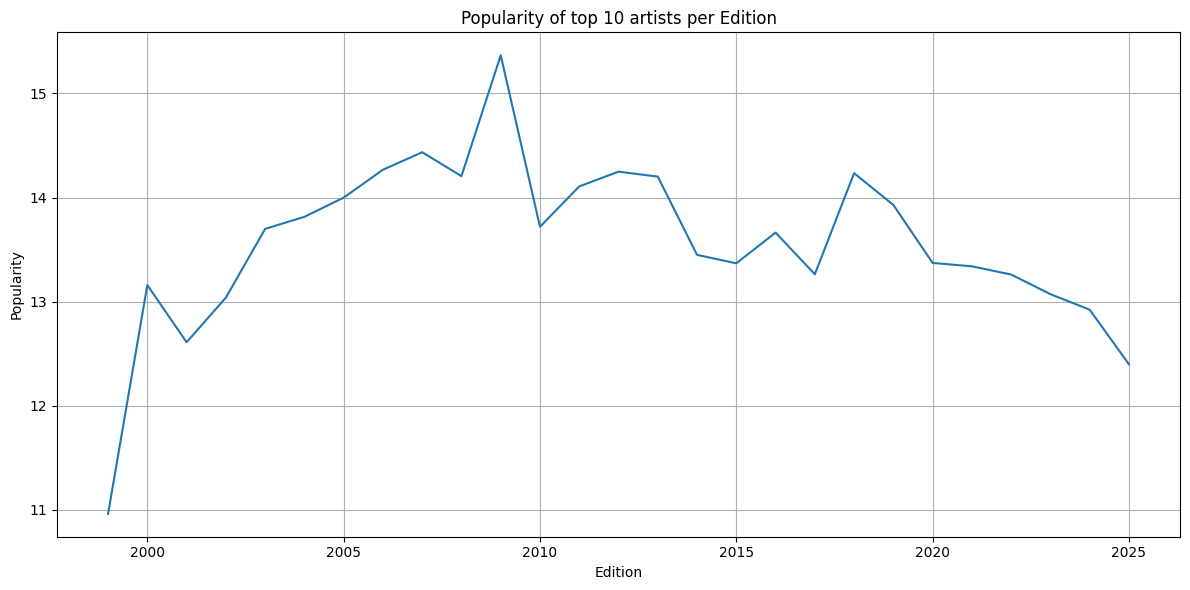

In [6]:
import matplotlib.pyplot as plt

# Zorg ervoor dat 'edition' numeriek is (voor de x-as)
df['edition'] = pd.to_numeric(df['edition'])

# Maak de plot
plt.figure(figsize=(12, 6))

# Plot de lijn
plt.plot(df['edition'], df['popularity'])

plt.xlabel('Edition')
plt.ylabel('Popularity')
plt.title('Popularity of top 10 artists per Edition')
plt.grid(True)
plt.tight_layout()
plt.show()
